# Time-dependent inputs

Models are often driven by an external signal: a ligand added to the medium, light, a drug dose, or an upstream species that isn't part of the model.
`mxlpy.fns_input` provides parameterised shapes for such inputs.
Their parameters are ordinary model parameters, so they can be fitted together with the kinetic ones.
This lets you estimate an unknown input from downstream measurements ("input estimation").

Unlike [protocols](basics.ipynb), which change parameters between integrations, inputs are model functions of `time`.
They work with fitting, forward sensitivities, symbolic analysis, serialisation and code generation.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from mxlpy import Model, Simulator, fit, fns, select
from mxlpy import fns_input as inp
from mxlpy.distributions import LogUniform

## Shapes

All inputs are used as derived values with `"time"` as the first argument.

- `smooth_step(t, level1, switch_time, level2, steepness)`: logistic switch
- `step(t, level1, switch_time, level2)`: hard switch. It is discontinuous, so prefer `smooth_step`, or a protocol if the levels aren't fitted
- `periodic_step(t, low, high, period, on_fraction, sharpness)`: smooth periodic switching, e.g. day and night
- `bolus(t, area, peak_time, width)`: Gaussian pulse with a given total area, e.g. an injected dose
- `multi_step(switch_times, steepness=...)`: factory for several switches at fixed times with fitted levels (`steepness=None` for hard switches)
- `cubic_spline(knots, positive=False, monotone=False, initial_slope=None)`: factory for a spline through fitted values at fixed knot times

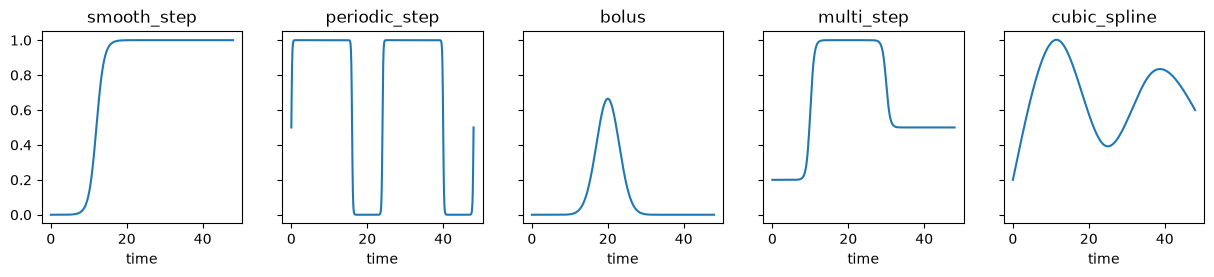

In [2]:
t = np.linspace(0, 48, 481)
spline = inp.cubic_spline([0, 12, 24, 36, 48])
shapes = {
    "smooth_step": [inp.smooth_step(x, 0.0, 12.0, 1.0, 1.0) for x in t],
    "periodic_step": [inp.periodic_step(x, 0.0, 1.0, 24.0, 2 / 3, 20.0) for x in t],
    "bolus": [inp.bolus(x, 5.0, 20.0, 3.0) for x in t],
    "multi_step": [
        inp.multi_step([10, 30], steepness=2.0)(x, 0.2, 1.0, 0.5) for x in t
    ],
    "cubic_spline": [spline(x, 0.2, 1.0, 0.4, 0.8, 0.6) for x in t],
}
fig, axs = plt.subplots(1, len(shapes), figsize=(15, 2.5), sharey=True)
for ax, (name, values) in zip(axs, shapes.items(), strict=True):
    ax.plot(t, values)
    ax.set(title=name, xlabel="time")
plt.show()

## Estimating an unknown stimulus

As an example, a species $x$ is produced in response to a stimulus $u(t)$ and degraded with rate constant $k$:

$$\frac{dx}{dt} = u(t) - k\,x$$

We only measure $x$, and we know $k$ from a separate experiment (e.g. the decay after washing the stimulus out).
The stimulus, unknown to us, is a pulse on top of a baseline.

In [3]:
def true_stimulus(t: float, baseline: float, area: float) -> float:
    return baseline + inp.bolus(t, area, 10.0, 3.0)


truth = (
    Model()
    .add_parameters({"k": 0.3, "baseline": 0.2, "area": 5.0})
    .add_variables({"x": 0.5})
    .add_derived("u", true_stimulus, args=["time", "baseline", "area"])
    .add_reaction("production", fns.constant, args=["u"], stoichiometry={"x": 1})
    .add_reaction(
        "degradation", fns.mass_action_1s, args=["x", "k"], stoichiometry={"x": -1}
    )
)
sigma = 0.02
times = np.linspace(0, 40, 41)
res = Simulator(truth).simulate_time_course(times).get_result().unwrap_or_err()
data = res.variables.loc[times, ["x"]]
data += np.random.default_rng(0).normal(0, sigma, data.shape)

We replace the unknown stimulus with a spline.
`add_spline_input` adds one parameter per knot (`u_0`, `u_1`, ...) and the derived value `u`.
With `positive=True` the spline interpolates the logarithms of the knot values, so the stimulus can't become negative.

In [4]:
def model(n_knots: int) -> Model:
    return (
        Model()
        .add_parameters({"k": 0.3})
        .add_variables({"x": 0.5})
        .add_spline_input(
            "u", knots=np.linspace(0, 40, n_knots), initial=0.5, positive=True
        )
        .add_reaction("production", fns.constant, args=["u"], stoichiometry={"x": 1})
        .add_reaction(
            "degradation", fns.mass_action_1s, args=["x", "k"], stoichiometry={"x": -1}
        )
    )

## How many knots?

Too few knots can't follow the pulse, and too many fit the noise.
We fit the knot values for several knot counts and compare the fits with `select.compare`, which ranks models by an information criterion (here BIC, see [model selection](model-selection.ipynb)).

In [5]:
knot_counts = [3, 5, 7, 9, 11]
p0 = {f"u_{i}": LogUniform(0.05, 2.0) for i in range(max(knot_counts))}
selection = select.compare(
    {f"{n} knots": model(n) for n in knot_counts},
    data,
    p0,
    loss_fn=fit.GaussianNll(sigma),
    criterion="bic",
    n_starts=5,
    transform="log",
)
selection.table[["k", "log_likelihood", "bic", "delta", "weight"]]

fits:   0%|          | 0/30 [00:00<?, ?it/s]

fits:   3%|▎         | 1/30 [00:04<02:16,  4.69s/it]

fits:   7%|▋         | 2/30 [00:05<00:59,  2.13s/it]

fits:  17%|█▋        | 5/30 [00:05<00:18,  1.33it/s]

fits:  23%|██▎       | 7/30 [00:06<00:15,  1.44it/s]

fits:  37%|███▋      | 11/30 [00:07<00:06,  2.89it/s]

... (2 outputs left out)

fits:  83%|████████▎ | 25/30 [00:07<00:00,  7.33it/s]

fits:  90%|█████████ | 27/30 [00:08<00:00,  7.68it/s]

fits: 100%|██████████| 30/30 [00:08<00:00,  3.71it/s]

,k,log_likelihood,bic,delta,weight
model,,,,,
9 knots,9,-11.148134,55.718416,0.000000,7.744166e-01
11 knots,11,-8.667982,58.185257,2.466840,2.255834e-01
7 knots,7,-154.903644,335.802292,280.083876,1.173637e-61
5 knots,5,-166.188135,350.944130,295.225714,6.046797e-65
3 knots,3,-6664.330573,13339.801862,13284.083446,0.000000e+00


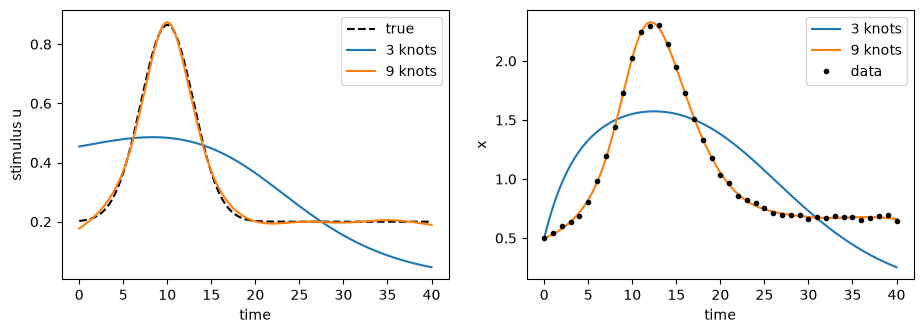

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
t = np.linspace(0, 40, 401)
ax1.plot(
    t,
    [true_stimulus(x, 0.2, 5.0) for x in t],
    color="black",
    linestyle="--",
    label="true",
)
for name in ["3 knots", selection.best_id]:
    candidate = selection[name]
    fitted = (
        Simulator(candidate.model).simulate_time_course(t).get_result().unwrap_or_err()
    )
    ax1.plot(t, fitted.get_combined()["u"], label=name)
    ax2.plot(t, fitted.variables["x"], label=name)
ax2.plot(data.index, data["x"], "o", color="black", markersize=3, label="data")
ax1.set(xlabel="time", ylabel="stimulus u")
ax2.set(xlabel="time", ylabel="x")
ax1.legend()
ax2.legend()
plt.show()

The best spline recovers the timing and size of the pulse from measurements of $x$ alone.

Why did we fix $k$? A flexible input can absorb any degradation constant: for every $k$, the input $u(t) = \frac{dx}{dt} + k\,x$ reproduces the same $x(t)$.
So $k$ and the input can't be estimated together from $x$ alone, and fitting both would give an arbitrary $k$ with a matching input.
Inputs are identifiable only together with enough independent information about the rest of the model.
For a confidence band of the estimated stimulus, profile the knot values with `identify.profile_likelihood`.

Other options of the spline:

- `monotone=True` uses a monotone cubic, which doesn't overshoot between knots
- `initial_slope=0.0` fixes the slope at the first knot, e.g. for an input that starts at steady state

Splines are piecewise polynomials whose expression grows roughly quadratically with the number of knots, so up to about 20 knots are cheap.